# Model 3: Telecom customer churn classification with an artificial neural network

### Authors
   * Jonathan Sancho Loaiza
   * Jennifer Lopez Miranda
   * Magdaleno Gomez Diaz

## Problem Analysis (CRISP-DM 1: Business Understanding)

A telecom company loses money every time a customer cancels the service, because winning a new customer through advertising and discounts costs several times more than keeping one who is already paying. The company calls this loss churn. If the customers who are about to leave could be named a month in advance, a retention team could call them with an offer before they cancel instead of after. The question this notebook answers is whether churn can be predicted from what the company already knows about each customer, the contract, the services, the payment method and the bill, well enough for the assistant of the project to answer "will this customer leave" with a probability.

The dataset is the Telco Customer Churn file published by IBM, with 7,043 customers of a fictional telecom company in California and, for each one, whether they left within the last month. The technique is an artificial neural network, taught in week twelve. The network here is a multilayer perceptron: the 30 encoded facts about a customer enter a first layer of neurons, each neuron multiplies them by its weights, adds a bias and passes the sum through an activation function, the result feeds a second layer, and a single output neuron with a sigmoid activation turns the last sum into a probability of churn. The weights are learned by backpropagation, which pushes each weight in the direction that lowers the binary cross entropy loss, the same loss the logistic regression of week eleven uses. The course notes add one more idea this dataset needs, oversampling, which is used in the second model.

### Libraries

In [1]:
# Dataset handling
import os
import numpy as np
import pandas as pd

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Model
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.utils import resample

# Split, evaluation and persistence
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score, recall_score, precision_score,
                             f1_score, roc_auc_score, roc_curve, classification_report)
import joblib

%matplotlib inline

RANDOM_STATE = 42

# Folder shared by every model of the project, read later by the REST API
MODELS_DIR = os.path.join('..', '..', 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

## Data Understanding (CRISP-DM 2)

The file is read straight from its public URL on GitHub, so the notebook runs without any manual download both on a local machine and in Google Colab.

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/refs/heads/master/data/Telco-Customer-Churn.csv'
telco = pd.read_csv(DATA_URL)
telco.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Each row is a customer. `customerID` is an identifier with no information. `gender`, `SeniorCitizen`, `Partner` and `Dependents` describe the person, `tenure` is the number of months the customer has been with the company, the next nine columns say which services the customer has, phone, internet and the add-ons on top of the internet, `Contract`, `PaperlessBilling` and `PaymentMethod` describe the commercial relationship, `MonthlyCharges` and `TotalCharges` are the bill of the current month and the sum of every bill so far, and `Churn` is the target, Yes if the customer left. The third customer, two months in, on a month-to-month contract paying by mailed check, left.

In [3]:
print("Rows and columns:", telco.shape)
telco.info()
print("Duplicated rows:", telco.duplicated().sum())

Rows and columns: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 n

There are 7,043 customers and 21 columns, no duplicated row and no missing value reported. Only three columns are numeric, `SeniorCitizen`, `tenure` and `MonthlyCharges`. `TotalCharges` is read as text, which is wrong for a sum of money, so something in that column is not a number. The other sixteen columns are text and have to be encoded before a network can read them.

In [4]:
# TotalCharges holds something that is not a number. Convert it and look at what failed
telco['TotalCharges'] = pd.to_numeric(telco['TotalCharges'], errors='coerce')
not_numeric = telco[telco['TotalCharges'].isna()]
print("Rows whose TotalCharges was not a number:", len(not_numeric))
not_numeric[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Rows whose TotalCharges was not a number: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Eleven rows held a blank instead of a number, and all eleven have a tenure of 0 months: these are customers who signed up in the current month and have not been billed yet, so their total is not missing, it is zero. None of them left. The preparation fills the eleven blanks with 0, which is the true value, rather than dropping the rows.

In [5]:
telco.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00,7032.00
mean,0.16,32.37,64.76,2283.30
std,0.37,24.56,30.09,2266.77
min,0.00,0.00,18.25,18.80
25%,0.00,9.00,35.50,401.45
50%,0.00,29.00,70.35,1397.48
75%,0.00,55.00,89.85,3794.74
max,1.00,72.00,118.75,8684.80


The table lists, for each numeric column, the count, the mean, the standard deviation, the minimum, the quartiles and the maximum. Sixteen percent of the customers are senior citizens. Tenure runs from 0 to 72 months with a median of 29, so half the customers have been with the company less than two and a half years. The monthly bill runs from 18 to 119 dollars with a median of 70. The total bill has a median of 1,397 dollars and a maximum of 8,685, and its count of 7,032 is the eleven blanks just found.

       Customers  Share %
Churn                    
No          5174     73.5
Yes         1869     26.5


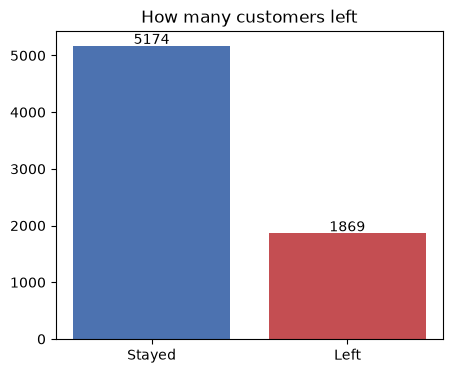

In [6]:
# The target, in counts and in percentage
counts = telco['Churn'].value_counts()
print(pd.DataFrame({'Customers': counts, 'Share %': (counts / len(telco) * 100).round(1)}))

plt.figure(figsize=(5, 4))
plt.bar(['Stayed', 'Left'], counts.values, color=['#4c72b0', '#c44e52'])
for i, value in enumerate(counts.values):
    plt.text(i, value + 30, str(value), ha='center')
plt.title('How many customers left')
plt.show()

The bar chart counts the two classes: 5,174 customers stayed and 1,869 left, 73.5 and 26.5 percent. The imbalance is milder than in a medical dataset but it still sets the floor of the evaluation: a model that answers "stays" for everyone is right 73.5 percent of the time, so an accuracy near 0.73 is the starting point and not a result. What the retention team needs is the share of the customers who leave that the model catches, which the course calls sensitivity or recall, and the evaluation is built around it.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

With a yes or no target the most readable exploration is the churn rate inside each value of each column. A rate of 3 percent against 43 percent is a fact a manager can act on, and it also says in advance which columns the network will lean on.

In [7]:
# Churn rate by the commercial columns
telco['churn'] = (telco['Churn'] == 'Yes').astype(int)
for column in ['Contract', 'InternetService', 'PaymentMethod', 'PaperlessBilling', 'SeniorCitizen']:
    rate = telco.groupby(column)['churn'].agg(['mean', 'count'])
    rate['mean'] = (rate['mean'] * 100).round(1)
    rate.columns = ['Churn rate %', 'Customers']
    print(rate)
    print()

                Churn rate %  Customers
Contract                               
Month-to-month          42.7       3875
One year                11.3       1473
Two year                 2.8       1695

                 Churn rate %  Customers
InternetService                         
DSL                      19.0       2421
Fiber optic              41.9       3096
No                        7.4       1526

                           Churn rate %  Customers
PaymentMethod                                     
Bank transfer (automatic)          16.7       1544
Credit card (automatic)            15.2       1522
Electronic check                   45.3       2365
Mailed check                       19.1       1612

                  Churn rate %  Customers
PaperlessBilling                         
No                        16.3       2872
Yes                       33.6       4171

               Churn rate %  Customers
SeniorCitizen                         
0                      23.6       5901


The contract is the strongest fact in the file. Customers on a month-to-month contract leave at 42.7 percent, on a one year contract at 11.3 and on a two year contract at 2.8, so a long contract divides the risk by fifteen. The type of internet is next: fiber optic customers leave at 41.9 percent, DSL at 19.0 and customers with no internet at 7.4, which is surprising for the faster service and suggests the fiber customers are either paying more or less happy with it. Paying by electronic check goes with a rate of 45.3 percent against 15 to 19 for every other method, and paperless billing with 33.6 against 16.3. Senior citizens leave at 41.7 percent against 23.6.

In [8]:
# Churn rate by the add-on services and the household columns
for column in ['TechSupport', 'OnlineSecurity', 'Partner', 'Dependents', 'gender']:
    rate = telco.groupby(column)['churn'].agg(['mean', 'count'])
    rate['mean'] = (rate['mean'] * 100).round(1)
    rate.columns = ['Churn rate %', 'Customers']
    print(rate)
    print()

                     Churn rate %  Customers
TechSupport                                 
No                           41.6       3473
No internet service           7.4       1526
Yes                          15.2       2044

                     Churn rate %  Customers
OnlineSecurity                              
No                           41.8       3498
No internet service           7.4       1526
Yes                          14.6       2019

         Churn rate %  Customers
Partner                         
No               33.0       3641
Yes              19.7       3402

            Churn rate %  Customers
Dependents                         
No                  31.3       4933
Yes                 15.5       2110

        Churn rate %  Customers
gender                         
Female          26.9       3488
Male            26.2       3555



Among the internet customers, the ones without technical support leave at 41.6 percent and the ones with it at 15.2, and online security shows the same split, 41.8 against 14.6. The 7.4 percent of the "No internet service" rows is the same group of 1,526 customers seen above. Customers with a partner leave at 19.7 percent against 33.0 without, and with dependents at 15.5 against 31.3. Gender changes nothing, 26.9 against 26.2, and it is the one column the exploration expects the network to ignore.

          Churn rate %  Customers
tenure                           
0 to 6            52.9       1481
7 to 12           35.9        705
13 to 24          28.7       1024
25 to 48          20.4       1594
49 to 72           9.5       2239

      tenure        MonthlyCharges        TotalCharges        
        mean median           mean median         mean  median
churn                                                         
0       37.6   38.0           61.3   64.4       2555.3  1683.6
1       18.0   10.0           74.4   79.6       1531.8   703.6


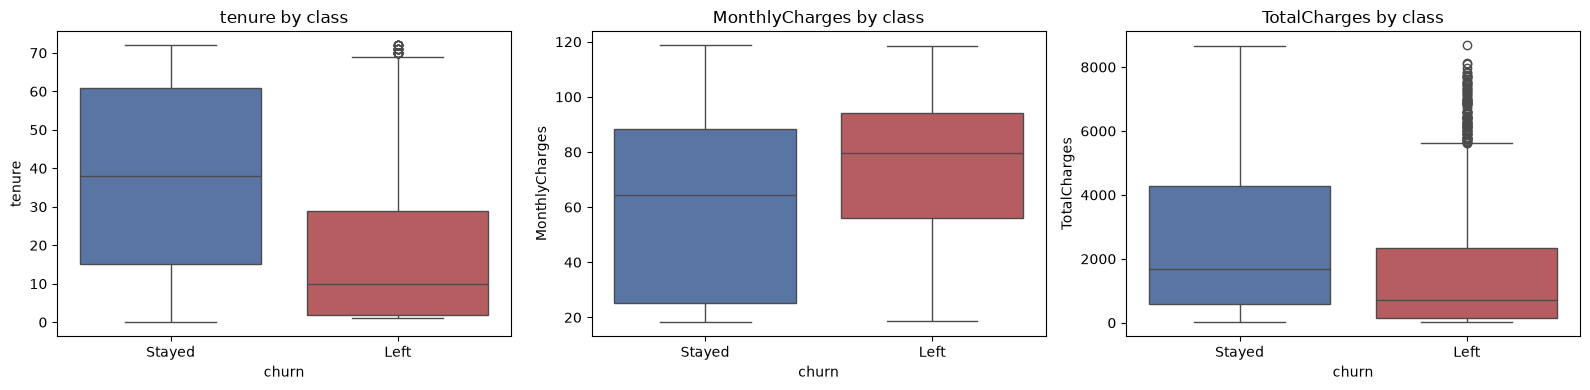

In [9]:
# Churn rate by how long the customer has stayed
TENURE_BANDS = [-1, 6, 12, 24, 48, 72]
BAND_LABELS = ['0 to 6', '7 to 12', '13 to 24', '25 to 48', '49 to 72']
by_tenure = telco.groupby(pd.cut(telco['tenure'], TENURE_BANDS, labels=BAND_LABELS), observed=True)['churn'].agg(['mean', 'count'])
by_tenure['mean'] = (by_tenure['mean'] * 100).round(1)
by_tenure.columns = ['Churn rate %', 'Customers']
print(by_tenure)

print()
print(telco.groupby('churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].agg(['mean', 'median']).round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, column in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    sns.boxplot(data=telco, x='churn', y=column, ax=ax, hue='churn', palette=['#4c72b0', '#c44e52'], legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Stayed', 'Left'])
    ax.set_title(column + ' by class')
plt.tight_layout()
plt.show()

The tenure bands tell the story of the first months. Customers in their first six months leave at 52.9 percent, more than half, and the rate falls in every band until it reaches 9.5 percent past four years. The customers who left had a median tenure of 10 months against 38 for the ones who stayed.

The box plots show one box per class, where the box holds the middle half of the customers, the line inside is the median, the whiskers reach the values still close to the box and the dots beyond are the extremes. The tenure boxes barely overlap. The monthly bill runs the other way: the customers who left paid a median of 79.6 dollars against 64.4, so the ones leaving are the ones paying the most, which is consistent with the fiber optic finding. The total bill is lower for the ones who left, 704 against 1,684 dollars, but only because they stayed fewer months, since the total is roughly the monthly bill times the tenure.

In [10]:
print(telco[['tenure', 'MonthlyCharges', 'TotalCharges']].corr().round(3))

                tenure  MonthlyCharges  TotalCharges
tenure           1.000           0.248         0.826
MonthlyCharges   0.248           1.000         0.651
TotalCharges     0.826           0.651         1.000


The correlation, which runs from -1 to 1 and measures how close two columns are to a straight line, confirms that `TotalCharges` is mostly a product of the other two: 0.83 with tenure and 0.65 with the monthly bill. A linear model would need to worry about that overlap. A neural network is not read through its weights and does not suffer from it in the same way, so the column is kept, but it is fair to expect that it adds little the other two do not already say.

In [11]:
# Preparation. The identifier and the text target go, the eleven blank totals become 0,
# and every text column becomes 0 or 1 columns, dropping the first value of each as
# the reference the others are compared against
TOTAL_CHARGES_FILL = 0.0
telco['TotalCharges'] = telco['TotalCharges'].fillna(TOTAL_CHARGES_FILL)

TARGET = 'churn'
encoded = pd.get_dummies(telco.drop(columns=['customerID', 'Churn']), drop_first=True, dtype=int)
FEATURES = [c for c in encoded.columns if c != TARGET]
print("Number of predictors:", len(FEATURES))
print(FEATURES)
encoded.head()

Number of predictors: 30
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


The table is now entirely numeric, 30 predictors and the target. A column such as `Contract_Two year` is 1 for a customer on a two year contract and 0 otherwise, and a customer with 0 in both contract columns is on the reference value, month-to-month. The same reading applies to the payment method, with bank transfer as the reference, and to the internet service, with DSL as the reference.

In [12]:
# Stratified 75 / 25 split, so both sides keep the 26.5 percent of churn
X = encoded[FEATURES]
y = encoded[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
print("Training customers:", len(X_train), "of which left:", int(y_train.sum()))
print("Test customers:", len(X_test), "of which left:", int(y_test.sum()))

Training customers: 5282 of which left: 1402
Test customers: 1761 of which left: 467


Training keeps 5,282 customers with 1,402 who left, and testing 1,761 customers with 467 who left. The split is stratified so the test set carries the same share of churn as the whole file, and every model below is scored on exactly these 1,761 customers.

## Machine Learning Model (CRISP-DM 4: Modeling)

The network is scikit-learn's multilayer perceptron, fitted inside a pipeline whose first step standardizes every predictor, subtracting the mean and dividing by the standard deviation. Standardizing matters more for a network than for a tree, because the weights start at small random values and a predictor written in thousands, such as the total bill, would dominate every sum from the first step. The network has two hidden layers of 32 and 16 neurons with the relu activation, which passes positive sums through and turns negative sums to zero, and one output neuron with a sigmoid, which maps the final sum to a probability between 0 and 1. It is trained by backpropagation on the binary cross entropy, and training stops early when the loss on a slice of the training data held aside for that purpose stops improving, which is the guard against a network that memorises the training customers.

Two versions are fitted. Model A is trained on the training set as it is, the literal reading of the technique. Model B is trained on an oversampled training set, where the customers who left are copied at random until they are as many as the ones who stayed, which is the answer the course notes give to unbalanced classes. Both are evaluated on the same untouched test set.

### Model A: network trained on the data as it is

Training rounds before early stopping: 38
Best accuracy on the held-aside slice: 0.805


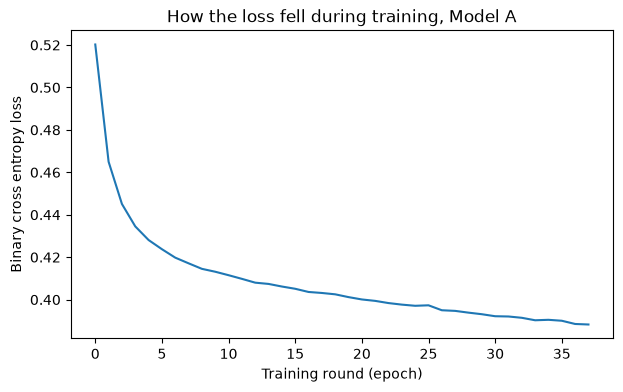

In [13]:
def build_network():
    return Pipeline([
        ('scale', StandardScaler()),
        ('network', MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500,
                                  early_stopping=True, random_state=RANDOM_STATE)),
    ])

model_plain = build_network().fit(X_train, y_train)
network_plain = model_plain.named_steps['network']
print("Training rounds before early stopping:", network_plain.n_iter_)
print("Best accuracy on the held-aside slice: %.3f" % network_plain.best_validation_score_)

plt.figure(figsize=(7, 4))
plt.plot(network_plain.loss_curve_)
plt.xlabel('Training round (epoch)')
plt.ylabel('Binary cross entropy loss')
plt.title('How the loss fell during training, Model A')
plt.show()

The curve is the loss after each pass over the training customers, which the course calls an epoch. The loss is the binary cross entropy, which is large when the network gives a low probability to a customer who left or a high one to a customer who stayed, and it falls as backpropagation adjusts the weights. It drops fast in the first ten rounds and then flattens, and the training stopped after 38 rounds because the accuracy on the slice held aside, 0.805 at its best, stopped improving. A network allowed to keep going past that point would keep lowering this curve while getting worse on new customers.

Threshold                 0.500
Accuracy                  0.790
Sensitivity (recall)      0.529
Specificity               0.885
Precision                 0.624
F1                        0.572
AUC                       0.840
Leavers found           247.000
Leavers missed          220.000
False alarms            149.000
Name: Model A, dtype: float64


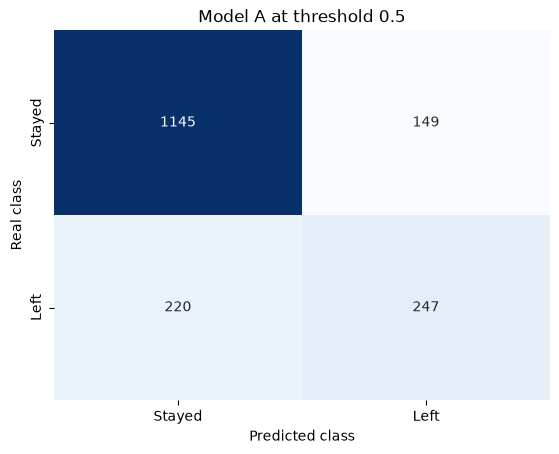

In [14]:
# Evaluation helper: confusion matrix, the rates and the AUC, at a chosen threshold
def evaluate(model, threshold, name):
    probability = model.predict_proba(X_test)[:, 1]
    predicted = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predicted).ravel()
    return pd.Series({
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, predicted),
        'Sensitivity (recall)': recall_score(y_test, predicted),
        'Specificity': tn / (tn + fp),
        'Precision': precision_score(y_test, predicted, zero_division=0),
        'F1': f1_score(y_test, predicted),
        'AUC': roc_auc_score(y_test, probability),
        'Leavers found': tp, 'Leavers missed': fn, 'False alarms': fp,
    }, name=name)

def show_confusion(model, threshold, title):
    predicted = (model.predict_proba(X_test)[:, 1] >= threshold).astype(int)
    matrix = confusion_matrix(y_test, predicted)
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Stayed', 'Left'], yticklabels=['Stayed', 'Left'])
    plt.xlabel('Predicted class')
    plt.ylabel('Real class')
    plt.title(title)
    plt.show()

DEFAULT_THRESHOLD = 0.5
print(evaluate(model_plain, DEFAULT_THRESHOLD, 'Model A').round(3))
show_confusion(model_plain, DEFAULT_THRESHOLD, 'Model A at threshold 0.5')

The confusion matrix has the real class in rows and the predicted class in columns: top left is customers correctly predicted to stay, bottom right is leavers correctly found, top right is false alarms and bottom left is leavers missed. Sensitivity, also called recall, is the share of the real leavers found. Specificity is the share of the stayers correctly left alone. Precision is the share of the flagged customers who really left. The AUC is the area under the ROC curve drawn later, 0.5 for a coin toss and 1 for a perfect ranking.

Model A reaches an accuracy of 0.790 and an AUC of 0.840, so the ranking is decent, but at the threshold of 0.5 it finds 247 of the 467 leavers and misses 220, a sensitivity of 0.529. It errs on the side of "stays": with 149 false alarms its precision of 0.624 is good, but a retention team working from this list would never hear about nearly half the customers who are about to go. That is the imbalance at work, since the network saw three stayers for every leaver and learned to be cautious about the minority.

### Model B: network trained on an oversampled training set

Oversampling copies rows of the minority class at random, with replacement, until it has as many rows as the majority. This is done on the training set only. The test set has to keep the real proportion of 26.5 percent, because the point of the test set is to measure what the model will do on real customers, and a test set with half leavers would report a sensitivity the company would never see. It is also done after the split, never before, since copying a customer before splitting could put the original in training and the copy in testing, and the network would then be scored on customers it has memorised.

Training rows before oversampling: 5282 {0: 3880, 1: 1402}
Training rows after oversampling: 7760 {0: 3880, 1: 3880}


Training rounds before early stopping: 42


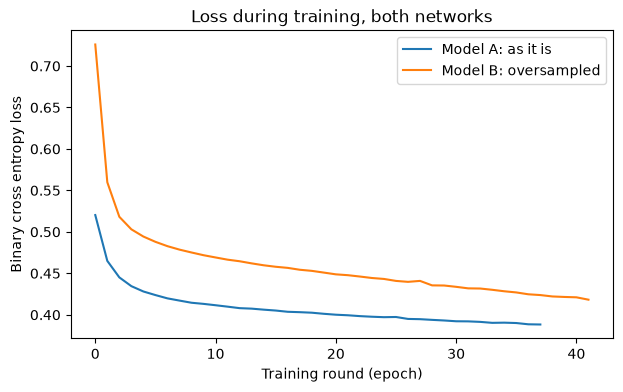

In [15]:
# Copy leavers at random, with replacement, until they match the stayers, training set only
training = pd.concat([X_train, y_train], axis=1)
stayers = training[training[TARGET] == 0]
leavers = training[training[TARGET] == 1]
leavers_oversampled = resample(leavers, replace=True, n_samples=len(stayers), random_state=RANDOM_STATE)
training_balanced = pd.concat([stayers, leavers_oversampled])

print("Training rows before oversampling:", len(training), training[TARGET].value_counts().to_dict())
print("Training rows after oversampling:", len(training_balanced), training_balanced[TARGET].value_counts().to_dict())

model_balanced = build_network().fit(training_balanced[FEATURES], training_balanced[TARGET])
network_balanced = model_balanced.named_steps['network']
print("Training rounds before early stopping:", network_balanced.n_iter_)

plt.figure(figsize=(7, 4))
plt.plot(network_plain.loss_curve_, label='Model A: as it is')
plt.plot(network_balanced.loss_curve_, label='Model B: oversampled')
plt.xlabel('Training round (epoch)')
plt.ylabel('Binary cross entropy loss')
plt.title('Loss during training, both networks')
plt.legend()
plt.show()

The training set grows from 5,282 rows to 7,760, with 3,880 of each class, the 1,402 leavers having been copied until they matched the 3,880 stayers. The second network trained for 42 rounds. Its loss curve starts higher, because a balanced set is harder to guess than one where three quarters of the answers are the same, and it flattens at a higher level for the same reason. Neither curve is better than the other on its own, what matters is the test set.

Threshold                 0.500
Accuracy                  0.755
Sensitivity (recall)      0.745
Specificity               0.759
Precision                 0.527
F1                        0.618
AUC                       0.831
Leavers found           348.000
Leavers missed          119.000
False alarms            312.000
Name: Model B, dtype: float64


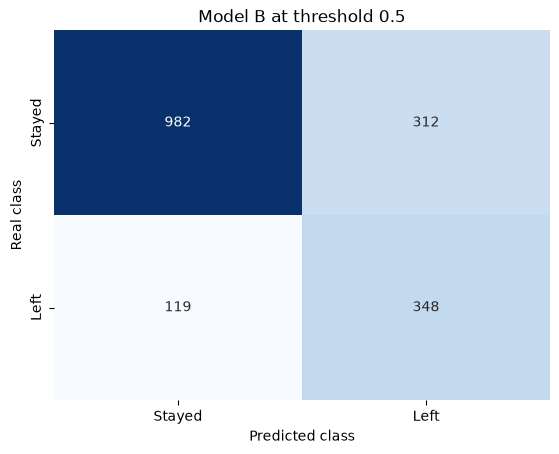

In [16]:
print(evaluate(model_balanced, DEFAULT_THRESHOLD, 'Model B').round(3))
show_confusion(model_balanced, DEFAULT_THRESHOLD, 'Model B at threshold 0.5')

At the same threshold Model B finds 348 of the 467 leavers, a sensitivity of 0.745, against 247 for Model A, that is, 101 more customers the retention team would hear about. The cost is on the other side of the matrix: false alarms rise from 149 to 312, so specificity falls from 0.885 to 0.759 and precision from 0.624 to 0.527. Accuracy drops from 0.790 to 0.755, and that drop is what a balanced training set buys, a model that no longer prefers the majority answer. The AUC falls slightly, 0.831 against 0.840, so the ranking behind the probabilities is about as good as before and the difference between the models is mostly where the threshold of 0.5 lands on that ranking.

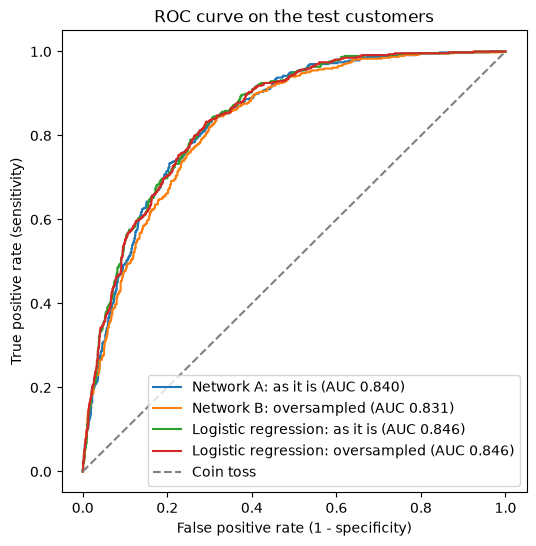

                      Logistic: as it is  Logistic: oversampled
Threshold                          0.500                  0.500
Accuracy                           0.806                  0.747
Sensitivity (recall)               0.555                  0.801
Specificity                        0.897                  0.728
Precision                          0.661                  0.515
F1                                 0.603                  0.627
AUC                                0.846                  0.846
Leavers found                    259.000                374.000
Leavers missed                   208.000                 93.000
False alarms                     133.000                352.000


In [17]:
# Is the network earning its complexity: a logistic regression on the same data, for reference
reference_plain = Pipeline([('scale', StandardScaler()),
                            ('logistic', LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
reference_balanced = Pipeline([('scale', StandardScaler()),
                               ('logistic', LogisticRegression(max_iter=1000))]).fit(
    training_balanced[FEATURES], training_balanced[TARGET])

plt.figure(figsize=(6, 6))
for model, name in [(model_plain, 'Network A: as it is'), (model_balanced, 'Network B: oversampled'),
                    (reference_plain, 'Logistic regression: as it is'),
                    (reference_balanced, 'Logistic regression: oversampled')]:
    probability = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probability)
    plt.plot(fpr, tpr, label='%s (AUC %.3f)' % (name, roc_auc_score(y_test, probability)))
plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Coin toss')
plt.xlabel('False positive rate (1 - specificity)')
plt.ylabel('True positive rate (sensitivity)')
plt.title('ROC curve on the test customers')
plt.legend()
plt.show()

print(pd.concat([evaluate(reference_plain, DEFAULT_THRESHOLD, 'Logistic: as it is'),
                 evaluate(reference_balanced, DEFAULT_THRESHOLD, 'Logistic: oversampled')], axis=1).round(3))

The ROC curve traces every threshold at once: each point is the sensitivity a model reaches, vertically, at the false alarm rate it pays for it, horizontally, and a curve closer to the top left corner ranks customers better. The four curves lie almost on top of each other. The logistic regression scores an AUC of 0.846 on both training sets, against 0.840 and 0.831 for the two networks, and at the threshold of 0.5 the oversampled logistic regression finds 374 leavers with 352 false alarms, a sensitivity of 0.801, slightly better than network B on both counts.

This is the honest finding of the notebook. On this dataset a two-layer network does not beat a straight-line model, and the reason is in the exploration: the facts that drive churn, the contract, the tenure, the payment method and the internet service, each push the risk in one direction on their own, without the interactions between predictors that a hidden layer exists to capture. The network is kept as the deliverable of this model because the technique of the week is the network, and it performs at the level of the linear model, but a company choosing on accuracy alone would take the simpler one.

In [18]:
# How the oversampled network behaves at several thresholds
THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7]
sweep = pd.concat([evaluate(model_balanced, t, 'threshold %.1f' % t) for t in THRESHOLDS], axis=1).T
print(sweep.round(3).to_string())

               Threshold  Accuracy  Sensitivity (recall)  Specificity  Precision     F1    AUC  Leavers found  Leavers missed  False alarms
threshold 0.3        0.3     0.677                 0.882        0.604      0.445  0.592  0.831          412.0            55.0         513.0
threshold 0.4        0.4     0.725                 0.842        0.683      0.489  0.619  0.831          393.0            74.0         410.0
threshold 0.5        0.5     0.755                 0.745        0.759      0.527  0.618  0.831          348.0           119.0         312.0
threshold 0.6        0.6     0.772                 0.649        0.816      0.560  0.601  0.831          303.0           164.0         238.0
threshold 0.7        0.7     0.785                 0.533        0.876      0.607  0.568  0.831          249.0           218.0         161.0


Each row is Model B with a different cut on its probability. Lowering the threshold to 0.3 finds 412 of the 467 leavers but flags 513 stayers, four in ten. Raising it to 0.7 flags 161 stayers but misses 218 leavers. The default of 0.5, with 348 found, 119 missed and 312 false alarms, is a reasonable middle for a retention team that can afford to call about a third of its customers. The threshold is a business decision that depends on the cost of a call against the value of a saved customer, so the probability itself is what gets stored and the API can apply whichever cut the company chooses.

## Evaluation (CRISP-DM 5)

The kept model is Model B at a threshold of 0.5. Its full report on the test customers follows, next to Model A for the record.

In [19]:
comparison = pd.concat([evaluate(model_plain, DEFAULT_THRESHOLD, 'Model A: as it is'),
                        evaluate(model_balanced, DEFAULT_THRESHOLD, 'Model B: oversampled')], axis=1)
print(comparison.round(3))
print()
print(classification_report(y_test, model_balanced.predict(X_test), target_names=['Stayed', 'Left']))

                      Model A: as it is  Model B: oversampled
Threshold                         0.500                 0.500
Accuracy                          0.790                 0.755
Sensitivity (recall)              0.529                 0.745
Specificity                       0.885                 0.759
Precision                         0.624                 0.527
F1                                0.572                 0.618
AUC                               0.840                 0.831
Leavers found                   247.000               348.000
Leavers missed                  220.000               119.000
False alarms                    149.000               312.000

              precision    recall  f1-score   support

      Stayed       0.89      0.76      0.82      1294
        Left       0.53      0.75      0.62       467

    accuracy                           0.76      1761
   macro avg       0.71      0.75      0.72      1761
weighted avg       0.80      0.76      0.77  

The report lists, for each class, the precision, the recall, their combination F1 and the support, which is the number of test customers in the class. For the customers who left, Model B reaches a recall of 0.75 with a precision of 0.53, and for the ones who stayed a recall of 0.76 with a precision of 0.89, so when the network says a customer stays it is right nine times in ten. The F1 of the leavers, 0.62, is the number that balances finding them against flagging the wrong ones, and it is higher than Model A's 0.57.

Model A wins on accuracy, 0.790 against 0.755, and that is stated before the choice. It wins by predicting "stays" more often on a test set where "stays" is right three times in four, and the price of that accuracy is 101 leavers it never flags. For a retention list the recall of the leavers is the metric that matters, and Model B raises it from 0.53 to 0.75.

## Results and Conclusion (CRISP-DM 6: Deployment)

The model kept is a multilayer perceptron with two hidden layers of 32 and 16 neurons, trained by backpropagation on an oversampled training set and applied at a threshold of 0.5 on 30 encoded predictors. On the 1,761 test customers it reaches an AUC of 0.831, a sensitivity of 0.745, a specificity of 0.759, a precision of 0.527, an F1 of 0.618 and an accuracy of 0.755. The same network trained on the data as it is, built first, reaches an accuracy of 0.790 and an AUC of 0.840 but a sensitivity of 0.529, and it was set aside because it misses nearly half the customers who leave. The trade is stated in the units of the problem: 101 more leavers found out of 467, in exchange for 163 more stayers called by the retention team without need.

Two limitations are stated plainly. First, a logistic regression on the same data reaches an AUC of 0.846 and a slightly higher recall, so the network adds complexity without adding accuracy here, which says the churn of this company is driven by facts that act one at a time, the contract, the tenure, the payment method, and not by combinations a hidden layer would discover. Second, the precision of 0.53 means that about half the customers on the list would not have left, so the list is a set of customers worth a call, not a prediction of who will cancel. The pipeline, which includes the scaler and the network, is saved below with its 30 predictor names, the threshold and the fill value of the total bill, so the REST API can build the same columns from a customer's record and predict without training again.

In [20]:
bundle = {
    'model': model_balanced,
    'features': FEATURES,
    'target': TARGET,
    'threshold': DEFAULT_THRESHOLD,
    'total_charges_fill': TOTAL_CHARGES_FILL,
}
MODEL_PATH = os.path.join(MODELS_DIR, 'telecom_churn_classification.joblib')
joblib.dump(bundle, MODEL_PATH)
print("Saved to", MODEL_PATH)

Saved to ../../models/telecom_churn_classification.joblib


In [21]:
# Reload and score one customer by hand: three months in, month-to-month contract, fiber optic,
# no security or support add-ons, paperless billing, electronic check, 85 dollars a month
loaded = joblib.load(MODEL_PATH)
customer = pd.DataFrame([dict.fromkeys(loaded['features'], 0)])
customer.loc[0, ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']] = [0, 3, 85.0, 255.0]
customer.loc[0, ['PhoneService_Yes', 'InternetService_Fiber optic', 'StreamingTV_Yes',
                 'PaperlessBilling_Yes', 'PaymentMethod_Electronic check']] = 1
probability = loaded['model'].predict_proba(customer)[0, 1]
print("Probability of leaving: %.3f" % probability)
print("Flagged for the retention team:", bool(probability >= loaded['threshold']))

Probability of leaving: 0.900
Flagged for the retention team: True


The reloaded pipeline gives this new fiber optic customer on a month-to-month contract paying by electronic check a probability of 0.90, well above the threshold, so the customer would be on the retention list, which is what the exploration's rates of 43, 42 and 45 percent for those three facts, compounded by a tenure under six months, imply. The API repeats this call: build the 30 columns from the customer's record, predict the probability and compare it with the stored threshold.